In [1]:
import pandas as pd
from h3 import h3
import glob
import numpy as np
from pandas import merge
import json
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import shape
from datetime import datetime, timedelta
import seaborn as sns

In [2]:
# Pandas Config
pd.set_option('display.max_columns', None)
pd.options.display.max_rows = 200

# ShareNow Data 
VEHICLE_TRIP = '/Users/demircanm/sciebo/IS3/Research_Projects/EmpiricalAnalysisSharedMobility/02_Data/final_dataset.csv'

# TIMEZONE
TIMEZONE = 'Europe/Berlin'



In [3]:
# Read Trips
trips = pd.read_csv(VEHICLE_TRIP)

/Users/demircanm/opt/anaconda3/envs/SharedMobility/lib/python3.7/site-packages/IPython/core/interactiveshell.py:3146: DtypeWarning: Columns (4,21,22,114) have mixed types.Specify dtype option on import or set low_memory=False.
  interactivity=interactivity, compiler=compiler, result=result)


In [6]:
trips["vehicleType"].unique()

array(['bycicle', 'bicycle', 'kick scooter', 'car', 'scooter'],
      dtype=object)

In [9]:
# Remove Bike Trips
trips = trips[(trips["vehicleType"] != "bicycle") & (trips["vehicleType"] != "bycicle")]


In [10]:
trips.groupby(["vehicleType"]).agg({"distance":"mean"})

,distance
vehicleType,
car,4451.397746
kick scooter,843.336567
scooter,2768.137264


<AxesSubplot:>

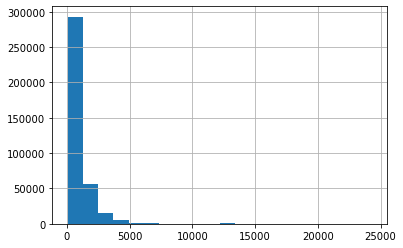

In [40]:
trips[(trips["vehicleType"] == "kick scooter")]["distance"].hist(bins = 20)

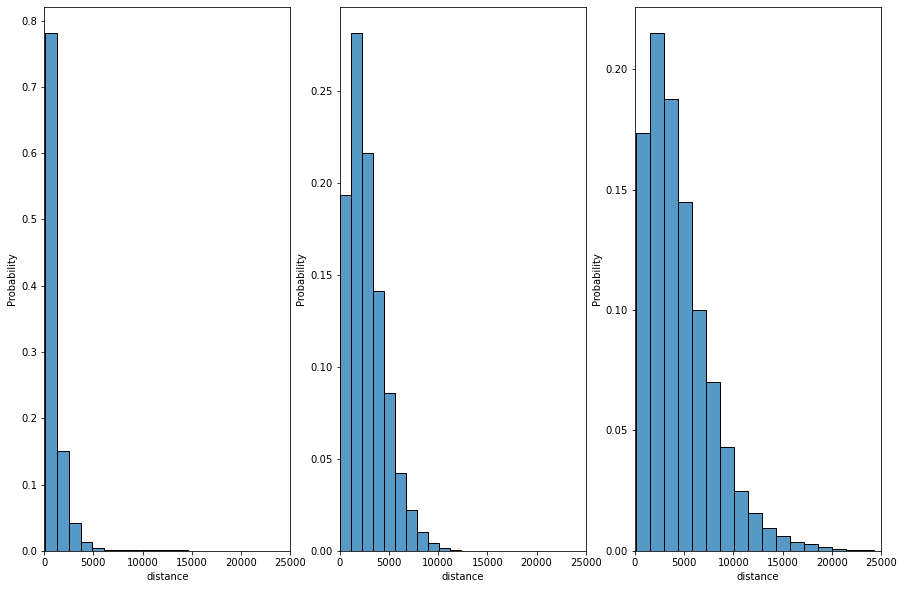

In [58]:
# Visualize Trip Characteristics 
import seaborn as sns

fig, (ax1, ax2, ax3) = plt.subplots(nrows=1, ncols=3, figsize=(15, 10))

sns.histplot(trips[(trips["vehicleType"] == "kick scooter")], x="distance", bins = 20, stat="probability", multiple="stack", ax= ax1)
ax1.set_xlim(0, 25000)

sns.histplot(trips[(trips["vehicleType"] == "scooter")], x="distance", bins = 20, stat="probability", multiple="stack", ax= ax2)
ax2.set_xlim(0, 25000)

sns.histplot(trips[(trips["vehicleType"] == "car")], x="distance", bins = 20, stat="probability", multiple="stack", ax= ax3)
ax3.set_xlim(0, 25000)

plt.show()


In [91]:
# Sample 

ks_samples = trips[(trips["vehicleType"] == "kick scooter")].sample(100000)
scooter_samples = trips[(trips["vehicleType"] == "scooter")].sample(100000)
car_samples = trips[(trips["vehicleType"] == "car")].sample(100000)

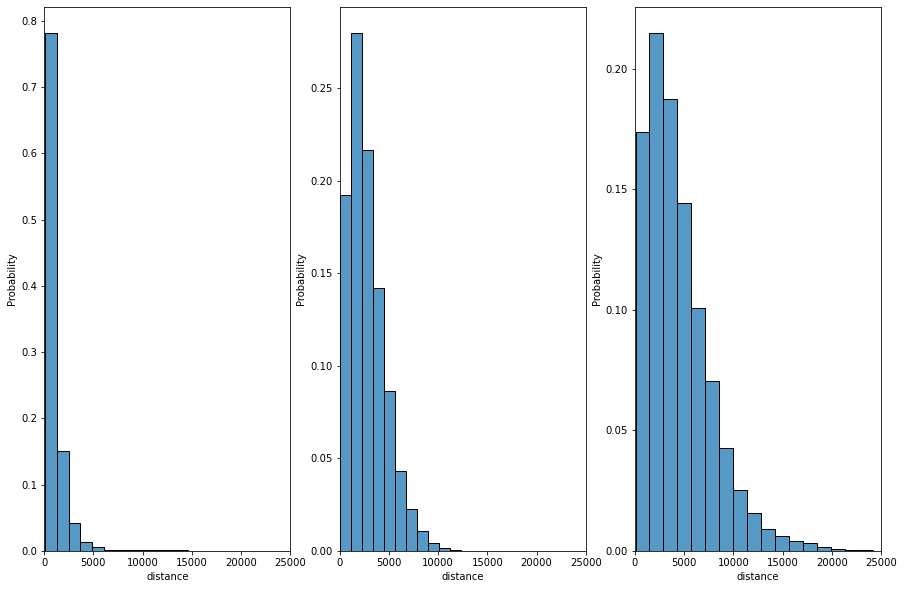

In [63]:
# Check whether sampled subset represents original set properly 
import seaborn as sns

fig, (ax1, ax2, ax3) = plt.subplots(nrows=1, ncols=3, figsize=(15, 10))

sns.histplot(ks_samples, x="distance", bins = 20, stat="probability", multiple="stack", ax= ax1)
ax1.set_xlim(0, 25000)

sns.histplot(scooter_samples, x="distance", bins = 20, stat="probability", multiple="stack", ax= ax2)
ax2.set_xlim(0, 25000)

sns.histplot(car_samples, x="distance", bins = 20, stat="probability", multiple="stack", ax= ax3)
ax3.set_xlim(0, 25000)

plt.show()


In [92]:
trip_sampled = pd.concat([ks_samples, scooter_samples, car_samples])

In [102]:
# https://www.statsmodels.org/stable/discretemod.html 
import statsmodels.api as sm

X = sm.add_constant(trip_sampled["distance"])
Y = trip_sampled["vehicleType"]
mnl_model = sm.MNLogit(Y, X).fit()

# spector_data = sm.datasets.spector.load_pandas()

Optimization terminated successfully.
         Current function value: 0.861756
         Iterations 8


In [103]:
# Print Choice Model Summary
mnl_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                          MNLogit Regression Results                          
==============================================================================
Dep. Variable:            vehicleType   No. Observations:               300000
Model:                        MNLogit   Df Residuals:                   299996
Method:                           MLE   Df Model:                            2
Date:                Wed, 14 Jul 2021   Pseudo R-squ.:                  0.2156
Time:                        11:08:18   Log-Likelihood:            -2.5853e+05
converged:                       True   LL-Null:                   -3.2958e+05
Covariance Type:            nonrobust   LLR p-value:                     0.000
=======================================================================================
vehicleType=kick scooter       coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------
const                        2.3758      0.009    254.739      0.000       2.358       2.394
distance                    -0.0013   4.95e-06   -252.450      0.000      -0.001      -0.001
--------------------------------------------------------------------------------------------
vehicleType=scooter       coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                   0.8324      0.008    103.831      0.000       0.817       0.848
distance               -0.0002   1.96e-06   -121.682      0.000      -0.000      -0.000
=======================================================================================
"""

In [95]:
# Predict Outcome based on Distance 
mnl_model.predict(X)

,0,1,2
245764,0.184650,0.490324,0.325026
133521,0.503405,0.040921,0.455675
2168379,0.246532,0.365231,0.388237
2192391,0.149271,0.569201,0.281529
213160,0.074998,0.754787,0.170215
...,...,...,...
1631398,0.767298,0.000201,0.232501
1852382,0.103300,0.680461,0.216240
1078636,0.242565,0.372766,0.384669
1803217,0.445746,0.082357,0.471898


In [145]:
# Save Model
mnl_model.save("mode_choice_model.pickle")

In [3]:
# Load Model 
from statsmodels.iolib.smpickle import load_pickle
mnl_model_loaded = load_pickle("../../data/choice_model/mode_choice_model.pickle")

## Visualization of Choice Probability 

In [35]:
# Predict single outcome (1, distance) (1 = constant)
# (Car, Kick Scooter, Scooter)
x = mnl_model_loaded.predict((1, 1500))
x = x.reshape((-1))

In [36]:
choice_probabilities = x.reshape((-1)) # Transform 2D array to 1D array

# Get Choice Index
choice = choice_probabilities.argmax()

# Calculate Substitution Bounds
lower_bound = choice_probabilities[choice] - 0.1

# Set Candidate Vehicle Choices to 1 based on given Trip Chars
mode_choices = [1 if x > lower_bound else 0 for x in choice_probabilities]

In [39]:
mode_choices

[0, 1, 1]

In [43]:
for idx, i in enumerate(mode_choices):
    print(i)
    print(idx)

0
0
1
1
1
2


In [142]:
# We generate test data from 0 meter to 10.000 meter and visualize the 
# probability densities

distance      = list(range(1,15000))
visualization = pd.DataFrame(distance, columns = ["distance"])
visualization = sm.add_constant(visualization)

# Predict Outcome
result = mnl_model.predict(visualization)

# Rename Columns 
result.columns = ["car", "kick scooter", "scooter"]

# Copy Distance Columns
result["distance"] = visualization["distance"]

In [143]:
result

,car,kick scooter,scooter,distance
0,0.071201,7.651647e-01,0.163634,1
1,0.071272,7.649698e-01,0.163758,2
2,0.071343,7.647749e-01,0.163882,3
3,0.071414,7.645799e-01,0.164006,4
4,0.071485,7.643847e-01,0.164130,5
...,...,...,...,...
14994,0.939534,7.313819e-08,0.060466,14995
14995,0.939548,7.304787e-08,0.060452,14996
14996,0.939561,7.295767e-08,0.060439,14997
14997,0.939575,7.286757e-08,0.060425,14998


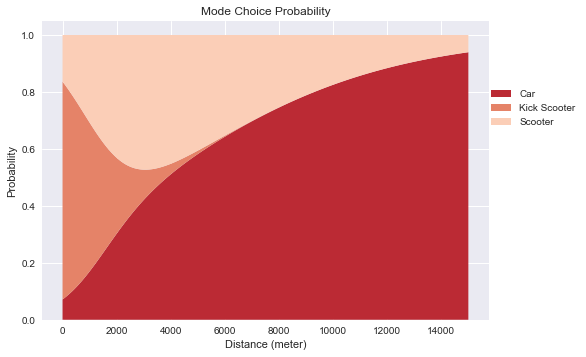

In [144]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
plt.style.use("seaborn")

colors = sns.color_palette("RdBu", 7)
labels=["Car", "Kick Scooter", "Scooter"]
plt.stackplot(result["distance"], result["car"], result["kick scooter"], result["scooter"], labels=labels, colors=colors)

plt.legend(loc = "upper center", bbox_to_anchor=(1.1, 0.8), ncol=1)
plt.title('Mode Choice Probability')
plt.ylabel('Probability')
plt.xlabel('Distance (meter)')
# plt.xticks(np.arange(2010,2020,step=1), rotation=40)

plt.show()